# Figure 9 — shear response in controlled simulations

Two panels replace the eight-panel diagnostic: one panel per native PSF width.
Color identifies the image method, and marker/line style identifies intrinsic
half-light radius. The horizontal axis shows the three nominal input S/N levels;
the separated noiseless points use the S/N-50 flux, with noise removed.

Presentation v02 selects radii 0.18 and 0.35 arcsec after inspecting the pilot,
where ResNet shows larger response gains over native images. It displays 48
unchanged values from 16 cells. The full three-radius comparison, including the
0.65-arcsec cases with weaker or negative gains, remains in the v01 exports and
archived notebook `revisions/09_shear_response_v01_three_radii.ipynb`.
No averaging over size, PSF, or S/N; no new inference or fitting. The original
paper ResNet is unchanged. The native PSF-correction curve remains omitted from
this presentation, with all results and failures preserved in the pilot report.
This is a proposed Figure 9, not yet installed in the manuscript.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
here = Path.cwd()
workspace = here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import ROOT, FIGURES, style, read_json, sha, export
%matplotlib inline
style(10)
VERSION = 'v02'
source = ROOT/'paper/diagnostics/shear_response_review_v01.json'
assert sha(source) == '10c06875e67a6c15fe08ac94e4f9323d702d78d4e83c08777e0864dd611579ca'
b = read_json(source)
assert b['complete'] and b['original_primary_comparison_reproduced']
assert len(b['cells']) == 24 and b['observed_common'] == 622
METHODS = [
    ('native_observed', 'Native observed', '#707070'),
    ('resnet_observed', 'ResNet observed', '#4477AA'),
    ('target_observed', 'High-resolution control', '#CC8833'),
]
SIZES = [(0.18, 'o', ':'), (0.35, '^', '--')]
SNRS = [20, 50, 100, None]
# Categorical spacing; noiseless is a separate experiment, not a finite S/N.
X = np.array([0., 1., 2., 3.2])
lookup = {(r['psf_fwhm'], r['half_light_radius'], r['snr']): r for r in b['cells']}
assert len(lookup) == 24
print('Frozen pilot: 24 cells, 622/624 common objects, 48 displayed responses in 16 selected cells.')

Frozen pilot: 24 cells, 622/624 common objects, 48 displayed responses in 16 selected cells.


Exported: fig09_shear_response_v02.pdf, fig09_shear_response_v02.svg, fig09_shear_response_v02.png


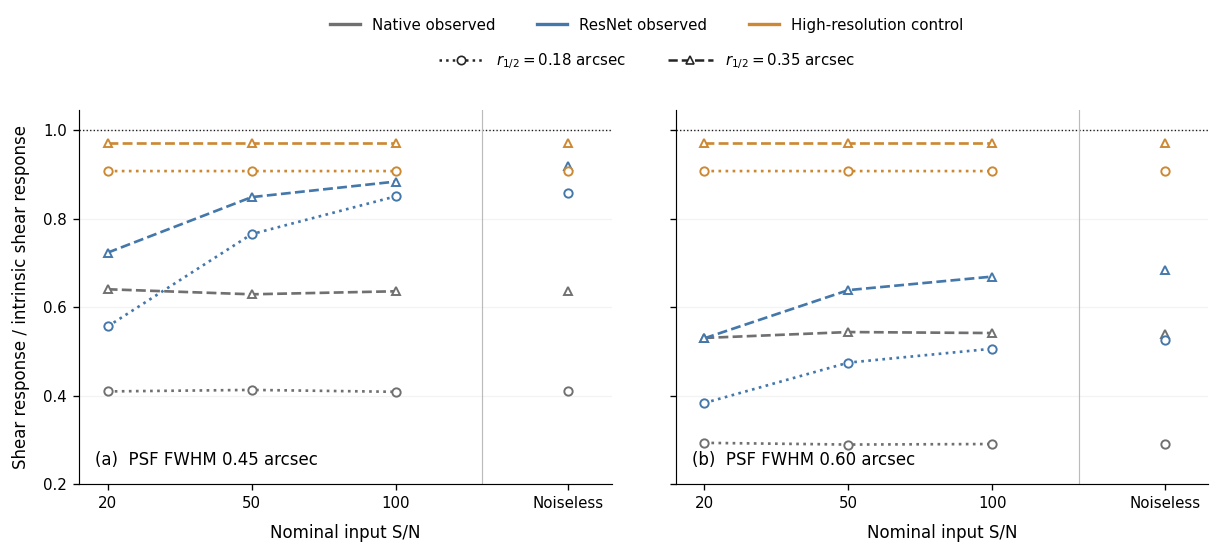

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.65), sharey=True)
plotted = []
for ax, psf, letter in zip(axes, [.45, .60], ['a', 'b']):
    ax.axhline(1, color='black', lw=.8, ls=':', zorder=0)
    ax.axvline(2.6, color='#BBBBBB', lw=.7, zorder=0)
    for name, label, color in METHODS:
        for radius, marker, ls in SIZES:
            rows = [lookup[(psf, radius, snr)] for snr in SNRS]
            assert all(r['methods'][name]['same_sample_available'] for r in rows)
            y = np.array([r['methods'][name]['relative_trace_response'] for r in rows])
            assert np.isfinite(y).all()
            # Do not connect to the separate noiseless experiment.
            line, = ax.plot(X[:3], y[:3], color=color, marker=marker, ls=ls,
                           lw=1.6, ms=5, mfc='white', mew=1.15, zorder=3)
            point, = ax.plot(X[3:], y[3:], color=color, marker=marker, ls='none',
                            ms=5, mfc='white', mew=1.15, zorder=3)
            np.testing.assert_array_equal(np.r_[line.get_ydata(), point.get_ydata()], y)
            for r, value in zip(rows, y):
                plotted.append(dict(psf_fwhm=psf, half_light_radius=radius, snr=r['snr'],
                                    method=name, response_ratio=float(value),
                                    common=r['observed_common'], attempted=r['attempted']))
    ax.text(.03, .04, f'({letter})  PSF FWHM {psf:.2f} arcsec',
            transform=ax.transAxes, ha='left', va='bottom', fontsize=10)
    ax.set_xticks(X, ['20', '50', '100', 'Noiseless'])
    ax.set_xlabel('Nominal input S/N', labelpad=8)
    ax.set_xlim(-.2, 3.5)
    ax.set_ylim(.2, 1.045)
    ax.set_yticks([.2, .4, .6, .8, 1.])
    ax.grid(axis='y', alpha=.14)
axes[0].set_ylabel('Shear response / intrinsic shear response', labelpad=8)
method_handles = [Line2D([], [], color=color, lw=2, label=label) for _, label, color in METHODS]
size_handles = [Line2D([], [], color='#252525', marker=marker, ls=ls, mfc='white',
                       lw=1.5, ms=5, label=rf'$r_{{1/2}}={radius:.2f}$ arcsec')
                for radius, marker, ls in SIZES]
fig.legend(handles=method_handles, loc='upper center', bbox_to_anchor=(.54, 1.01),
           ncol=3, frameon=False, fontsize=9, columnspacing=2.8)
fig.legend(handles=size_handles, loc='upper center', bbox_to_anchor=(.54, .95),
           ncol=2, frameon=False, fontsize=9, columnspacing=2.8, handlelength=3)
fig.subplots_adjust(left=.085, right=.99, bottom=.15, top=.82, wspace=.12)
assert len(plotted) == 48
paths = export(fig, f'fig09_shear_response_{VERSION}', '09_shear_response.ipynb',
               [source], settings=dict(version=VERSION, panels='native PSF width',
                   displayed_methods=[m[0] for m in METHODS], sizes=[s[0] for s in SIZES],
                   snr_order=SNRS, categorical_positions=X.tolist(),
                   size_selection='Post hoc: retain 0.18 and 0.35 arcsec, where ResNet response gains are larger.',
                   omitted_sizes=[0.65], full_comparison='fig09_shear_response_v01',
                   response='trace(R) / trace(R_intrinsic)', values=plotted,
                   unchanged_numerical_results=True, native_psf_correction_displayed=False),
               status='Figure 9 draft; synthetic pilot; original ResNet; not calibrated shear')
plt.show()

## Working caption

Shear response of observed adaptive galaxy shapes in controlled simulations.
Panels (a) and (b) use native Gaussian PSFs with FWHM 0.45 and 0.60 arcsec,
respectively. Colors distinguish native images, the original ResNet outputs,
and a noiseless high-resolution control; symbols and line styles identify
intrinsic half-light radii of 0.18 and 0.35 arcsec, selected after inspecting the
pilot to illustrate the stronger ResNet response gains. The complete three-size
comparison is retained in the diagnostic records. We plot
$\mathrm{tr}(R)/\mathrm{tr}(R_{\rm intrinsic})$, where
$R_{ij}=[\langle e_i\rangle_{g_j=+0.01}-\langle e_i\rangle_{g_j=-0.01}]/0.02$.
The dotted horizontal line marks the intrinsic response. Values below one
indicate suppressed sensitivity to applied shear; this ratio is not shape
accuracy or a calibrated multiplicative shear bias.

The S/N axis is categorical, with connecting lines serving as guides to the eye.
Points to the right of the separator have no input noise and use the same flux
as the nominal S/N-50 cases. Intrinsic profiles are exponential with distortion
magnitude 0.35 and eight orientations. Noisy cells have four noise realizations
per orientation; the same realization is used across all five shear branches.
Each cell compares exactly the same objects measurable in all three displayed
methods and all branches: 32/32 objects in each noisy cell except 30/32 at
FWHM 0.45 arcsec, radius 0.18 arcsec, and S/N 20; noiseless cells have 8/8.
These are pilot point estimates without uncertainty intervals.

The high-resolution control has a circular 0.08-arcsec Gaussian PSF and is not a
validated JWST simulation. No PSF correction is applied to any displayed method.
Native REGAUSS results, including the failures at FWHM 0.45 arcsec, are retained
in the diagnostic report but omitted here. ResNet restores some shear sensitivity,
with performance dependent on size, PSF, and noise. The omitted 0.65-arcsec
cases show smaller gains and, at S/N 20, a weaker response than the native
images for both PSFs. These idealized
simulations do not establish calibrated weak-lensing performance.

## Numerical values and coverage

All 48 plotted values are copied exactly from the verified pilot results.
The full response matrices and the omitted PSF-correction measurements remain in
`paper/diagnostics/shear_response_review_v01.json`; the protocol and interpretation
are in `paper/shear_response_pilot.md`.

In [3]:
table = pd.DataFrame(plotted)
display(table.pivot(index=['psf_fwhm', 'half_light_radius', 'snr'],
                    columns='method', values='response_ratio'))
print('All 48 plotted responses checked against frozen inputs; no samples recomputed.')

method                            native_observed  resnet_observed  \
psf_fwhm half_light_radius snr                                       
0.45     0.18              NaN           0.409312         0.857675   
                           20.0          0.409241         0.556114   
                           50.0          0.412654         0.764716   
                           100.0         0.408386         0.850160   
         0.35              NaN           0.635455         0.918163   
                           20.0          0.640130         0.722900   
                           50.0          0.628760         0.848410   
                           100.0         0.635569         0.883520   
0.60     0.18              NaN           0.290124         0.525929   
                           20.0          0.292993         0.383097   
                           50.0          0.289168         0.474342   
                           100.0         0.290356         0.505778   
         0.35              NaN           0.539699         0.683877   
                           20.0          0.530104         0.529291   
                           50.0          0.543430         0.638214   
                           100.0         0.541206         0.668804   

method                            target_observed  
psf_fwhm half_light_radius snr                     
0.45     0.18              NaN           0.907294  
                           20.0          0.907293  
                           50.0          0.907294  
                           100.0         0.907294  
         0.35              NaN           0.971326  
                           20.0          0.971326  
                           50.0          0.971326  
                           100.0         0.971326  
0.60     0.18              NaN           0.907294  
                           20.0          0.907293  
                           50.0          0.907294  
                           100.0         0.907294  
         0.35              NaN           0.971326  
                           20.0          0.971326  
                           50.0          0.971326  
                           100.0         0.971326

All 48 plotted responses checked against frozen inputs; no samples recomputed.
